# Prediction Results Plots

Grouped plots comparing gesture and phase prediction results across tasks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 450,
    "font.size": 16.5,
    "axes.labelsize": 18,
    "axes.titlesize": 21,
    "legend.fontsize": 17,
})

In [2]:
repo_root = Path.cwd()
if repo_root.name == "utils":
    repo_root = repo_root.parents[1]

results_path = repo_root / "documents" / "accuracies" / "report_results.csv"
results = pd.read_csv(results_path)

task_order = ["Suturing", "Needle Passing", "Knot Tying"]
task_labels = {
    "Suturing": "Suturing",
    "Needle_Passing": "Needle Passing",
    "Needle Passing": "Needle Passing",
    "Knot_Tying": "Knot Tying",
    "Knot Tying": "Knot Tying",
}

scratch = (
    results.loc[
        (results["kind"] == "Gesture") & (results["type"] == "from scratch"),
        ["task", "accuracy", "weighted_f1"],
    ]
    .assign(task=lambda df: df["task"].map(task_labels))
    .set_index("task")
    .reindex(task_order)
)

In [3]:
transfer = pd.DataFrame(
    [
        ("Suturing", 42, 0.8288, 0.8545, 0.8310),
        ("Suturing", 257, 0.8192, 0.8512, 0.8287),
        ("Suturing", 3121, 0.8400, 0.8337, 0.8242),
        ("Suturing", 7576, 0.8369, 0.8409, 0.8274),
        ("Suturing", 9438, 0.8350, 0.8398, 0.8443),
        ("Needle Passing", 42, 0.7634, 0.8098, 0.7664),
        ("Needle Passing", 257, 0.7808, 0.7853, 0.7821),
        ("Needle Passing", 3121, 0.7263, 0.8164, 0.7840),
        ("Needle Passing", 7576, 0.7761, 0.7928, 0.7576),
        ("Needle Passing", 9438, 0.7579, 0.7972, 0.7653),
        ("Knot Tying", 42, 0.9658, 0.8316, 0.8269),
        ("Knot Tying", 257, 0.9584, 0.8524, 0.8418),
        ("Knot Tying", 3121, 0.4618, 0.8188, 0.8564),
        ("Knot Tying", 7576, 0.6059, 0.8442, 0.8600),
        ("Knot Tying", 9438, 0.9563, 0.8415, 0.8722),
    ],
    columns=["task", "seed", "phase_accuracy", "phase_to_gesture_accuracy", "gesture_only_accuracy"],
)

transfer_summary = (
    transfer.groupby("task")["phase_to_gesture_accuracy"]
    .agg(mean="mean", min="min", max="max")
    .reindex(task_order)
)

In [4]:
grs = pd.DataFrame(
    [
        ("Suturing", 0.8321, 0.8292),
        ("Needle Passing", 0.7844, 0.7862),
        ("Knot Tying", 0.8440, 0.8426),
    ],
    columns=["task", "accuracy", "f1"],
).set_index("task").reindex(task_order)

In [5]:
accuracy_plot = pd.DataFrame(
    {
        "Gesture from scratch": scratch["accuracy"],
        "Gesture by GRS model": grs["accuracy"],
    },
    index=task_order,
)

accuracy_errors = pd.DataFrame(0.0, index=task_order, columns=accuracy_plot.columns)

accuracy_plot

,Gesture from scratch,Gesture by GRS model
Suturing,0.836323,0.8321
Needle Passing,0.801262,0.7844
Knot Tying,0.860825,0.8440


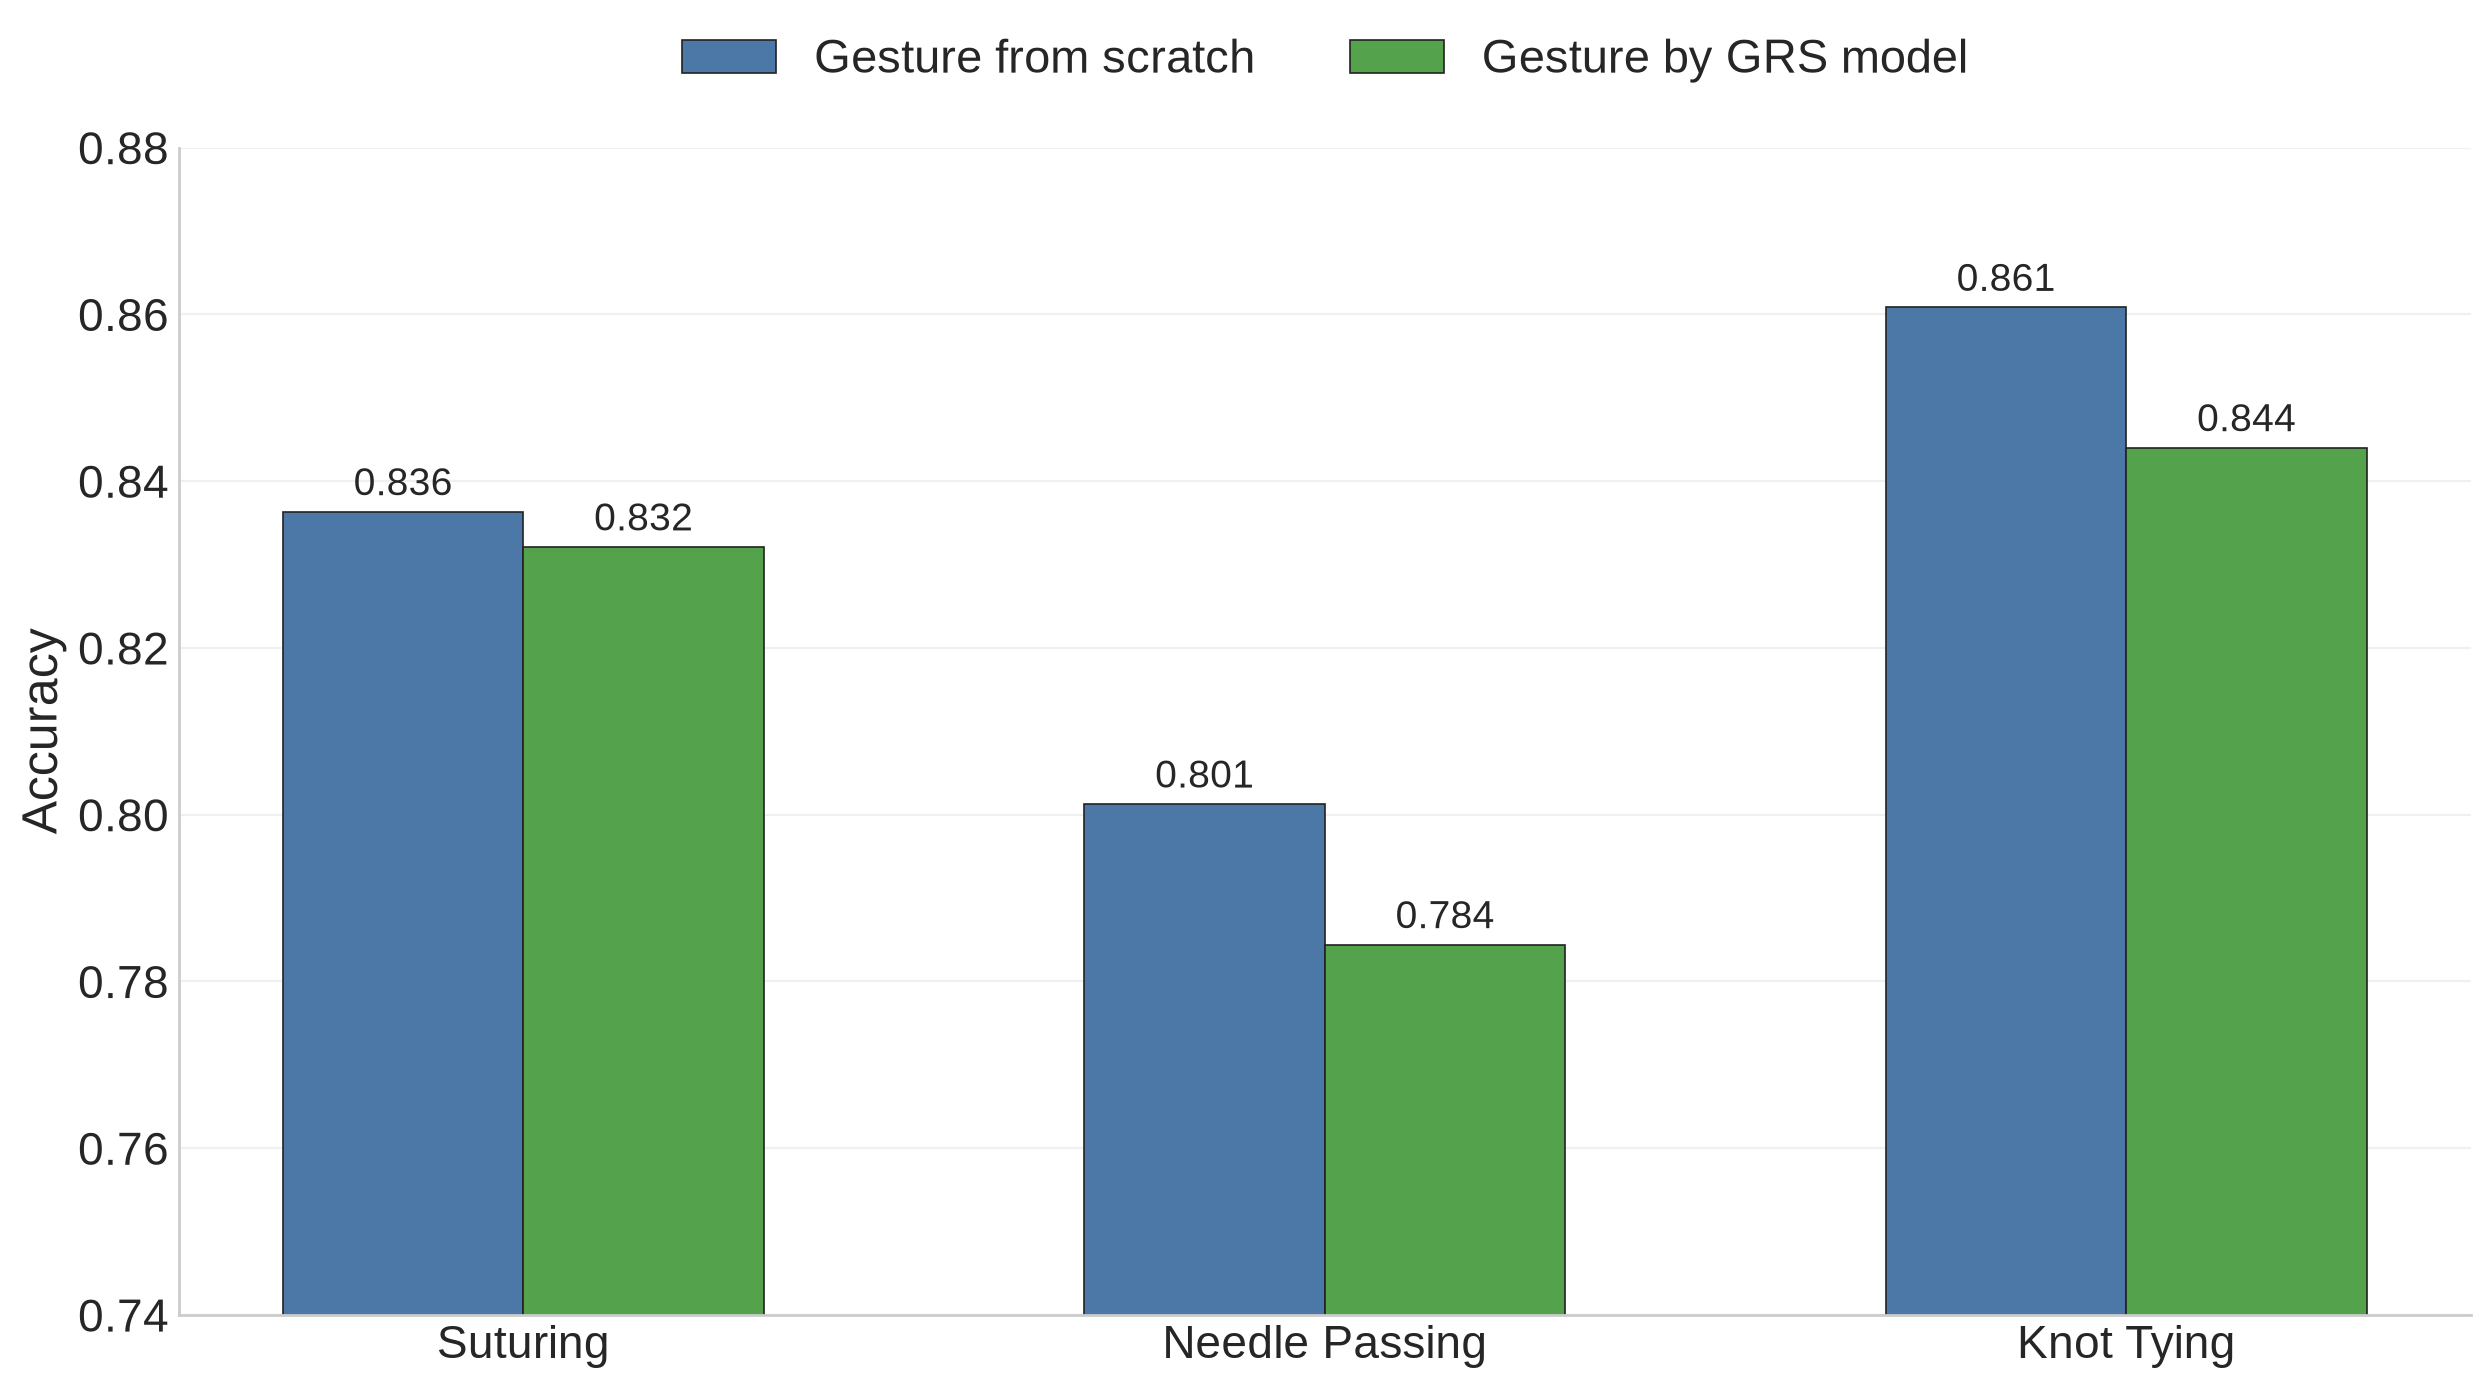

In [6]:
accuracy_fig, ax = plt.subplots(figsize=(12.75, 7.2))

x = np.arange(len(task_order))
bar_width = 0.30
colors = ["#4C78A8", "#54A24B"]

for i, (label, color) in enumerate(zip(accuracy_plot.columns, colors)):
    offset = (i - 0.5) * bar_width
    yerr = accuracy_errors[label].to_numpy()
    bars = ax.bar(
        x + offset,
        accuracy_plot[label].to_numpy(),
        bar_width,
        label=label,
        color=color,
        edgecolor="#222222",
        linewidth=0.6,
        yerr=yerr if yerr.any() else None,
        capsize=4,
        error_kw={"elinewidth": 1.0, "capthick": 1.0, "ecolor": "#333333"},
    )
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in accuracy_plot[label]], padding=3, fontsize=14)

ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(task_order)
ax.set_ylim(0.74, 0.88)
ax.legend(ncols=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.13))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.28)
ax.grid(axis="x", visible=False)

accuracy_fig.tight_layout()
plt.show()

In [7]:
phase_scratch = (
    results.loc[
        (results["kind"] == "Phase") & (results["type"] == "from scratch"),
        ["task", "accuracy", "weighted_f1"],
    ]
    .assign(task=lambda df: df["task"].map(task_labels))
    .set_index("task")
    .reindex(task_order)
)

phase_transfer_types = ["full model fine-tuning", "frozen encoder", "linear probe"]
phase_transfer = (
    results.loc[
        (results["kind"] == "Phase") & (results["type"].isin(phase_transfer_types)),
        ["task", "type", "accuracy", "weighted_f1"],
    ]
    .assign(task=lambda df: df["task"].map(task_labels))
)

phase_transfer_summary = (
    phase_transfer.groupby("task")["accuracy"]
    .agg(mean="mean", min="min", max="max")
    .reindex(task_order)
)

phase_accuracy_plot = pd.DataFrame(
    {
        "Phase from scratch": phase_scratch["accuracy"],
        "Gesture->Phase transfer": phase_transfer_summary["mean"],
    },
    index=task_order,
)

phase_accuracy_mins = phase_accuracy_plot.copy()
phase_accuracy_mins["Gesture->Phase transfer"] = phase_transfer_summary["min"]

phase_accuracy_maxs = phase_accuracy_plot.copy()
phase_accuracy_maxs["Gesture->Phase transfer"] = phase_transfer_summary["max"]

phase_accuracy_plot


,Phase from scratch,Gesture->Phase transfer
Suturing,0.842357,0.826449
Needle Passing,0.805959,0.752213
Knot Tying,0.872426,0.826375


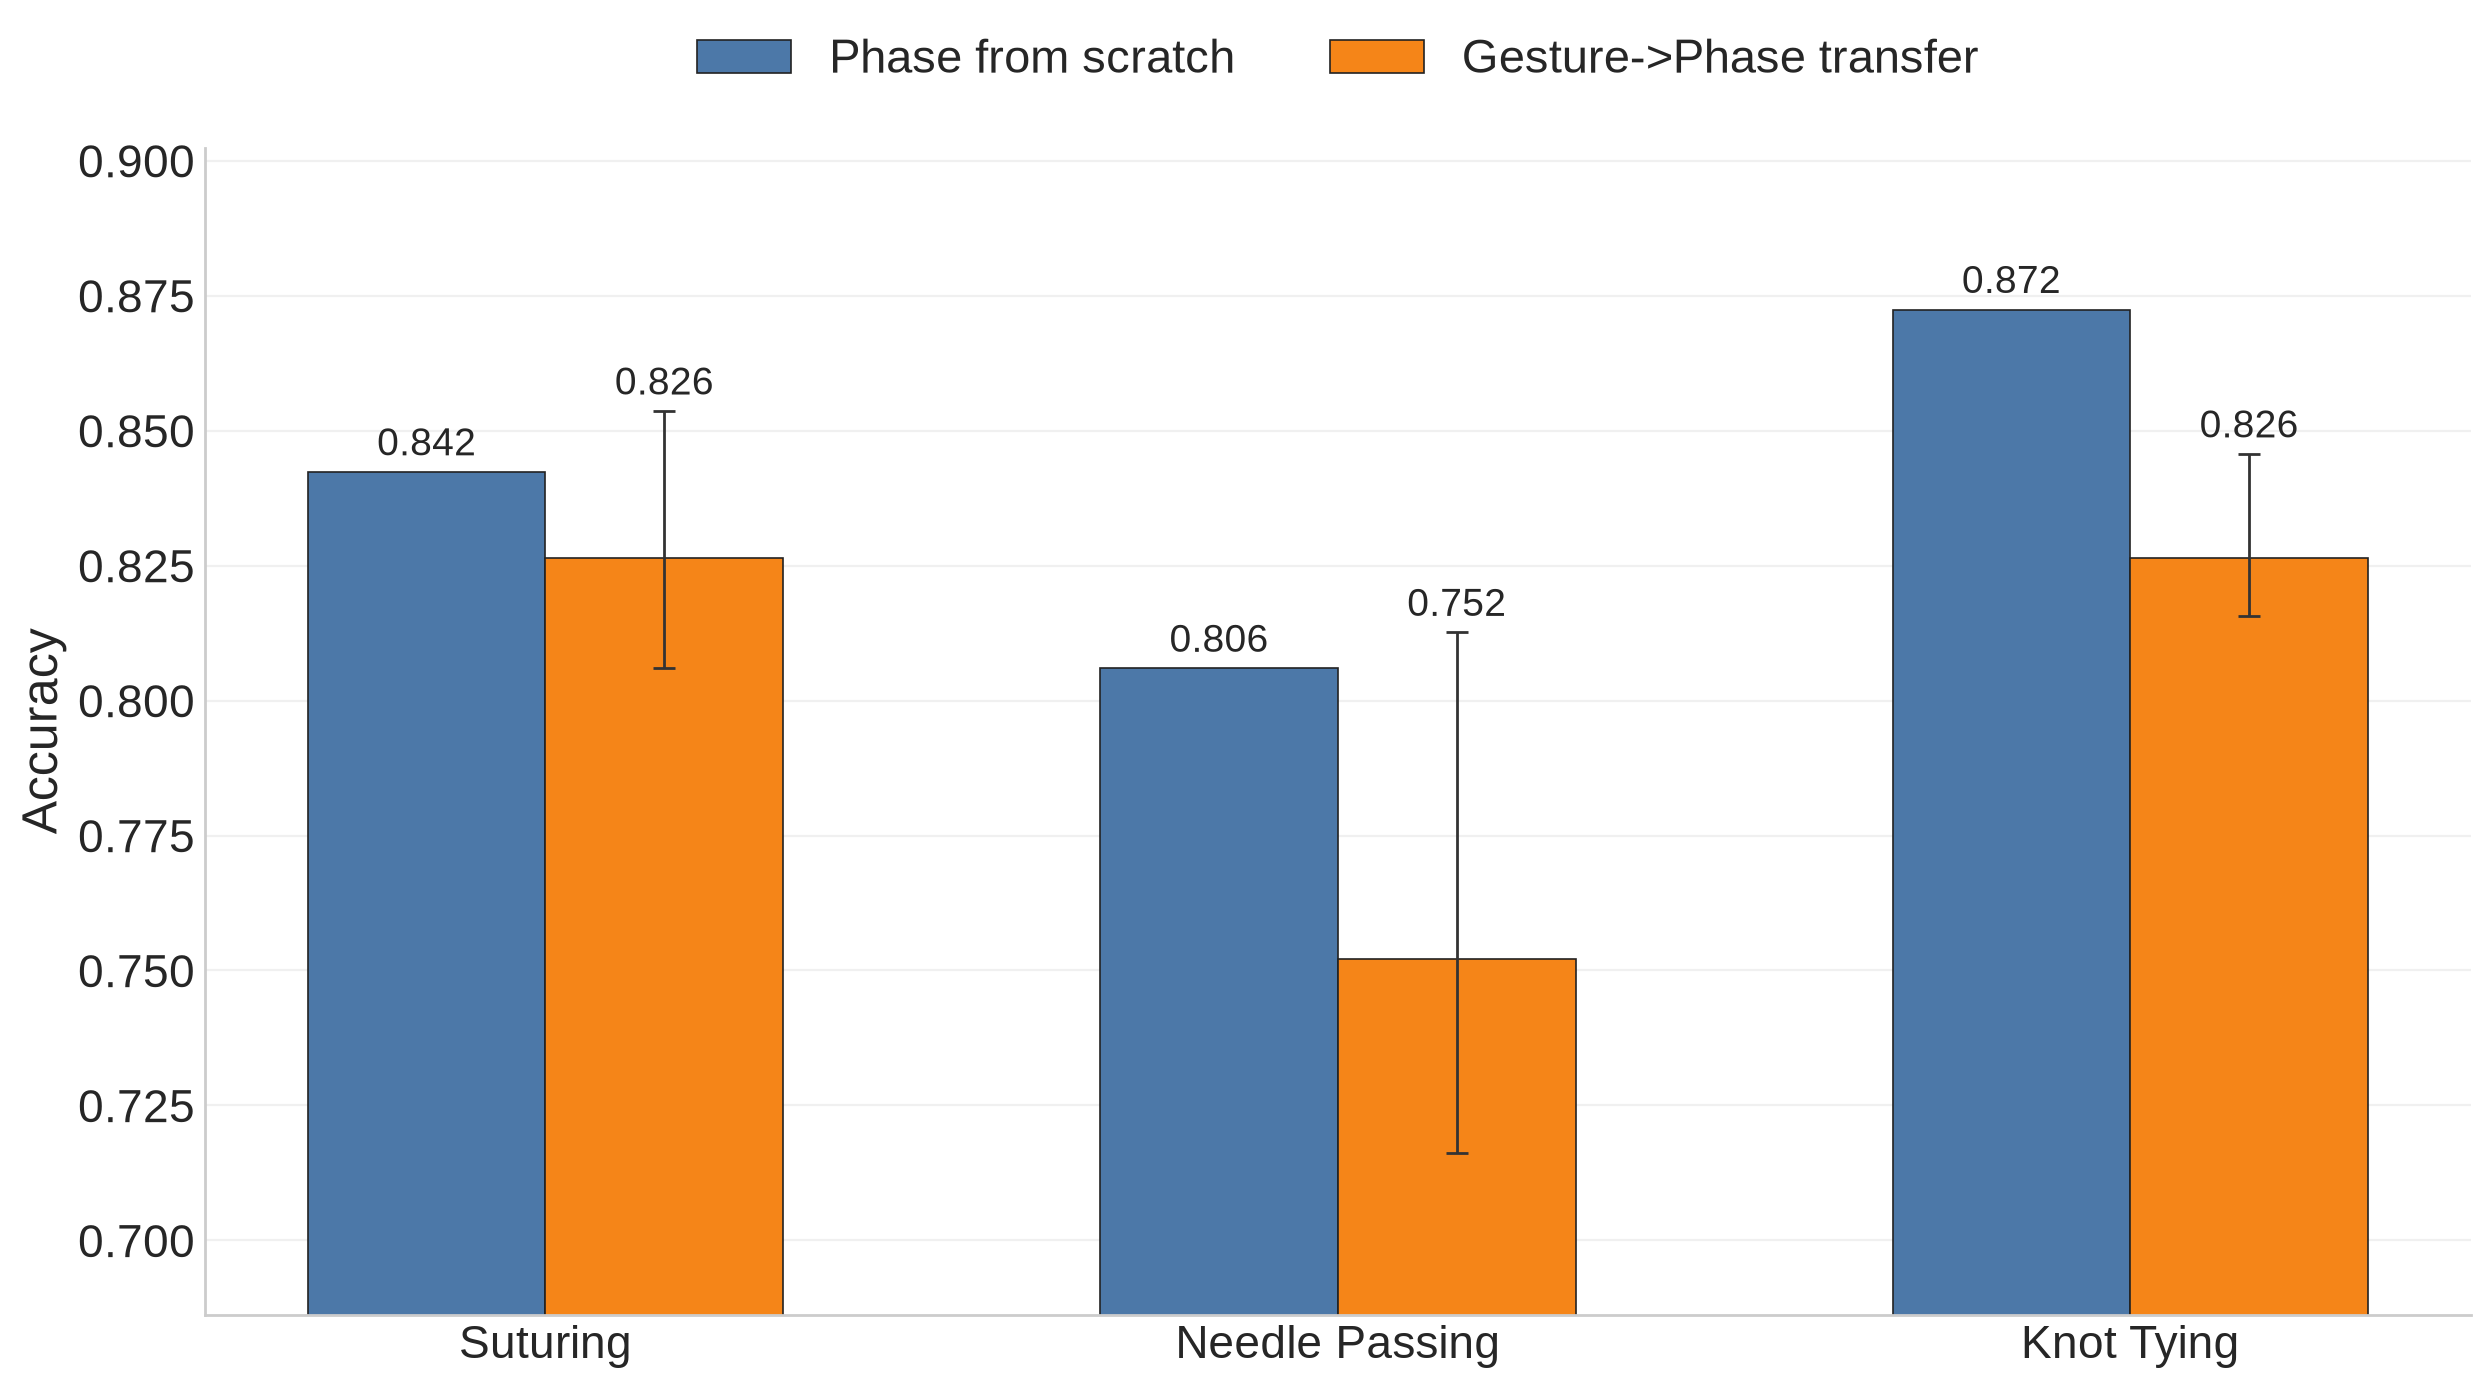

In [8]:
phase_fig, ax = plt.subplots(figsize=(12.75, 7.2))

x = np.arange(len(task_order))
bar_width = 0.30
colors = ["#4C78A8", "#F58518"]

for i, (label, color) in enumerate(zip(phase_accuracy_plot.columns, colors)):
    offset = (i - 0.5) * bar_width
    values = phase_accuracy_plot[label].to_numpy()
    mins = phase_accuracy_mins[label].to_numpy()
    maxs = phase_accuracy_maxs[label].to_numpy()
    yerr = np.vstack([values - mins, maxs - values])
    bars = ax.bar(
        x + offset,
        values,
        bar_width,
        label=label,
        color=color,
        edgecolor="#222222",
        linewidth=0.6,
        yerr=yerr if yerr.any() else None,
        capsize=4,
        error_kw={"elinewidth": 1.0, "capthick": 1.0, "ecolor": "#333333"},
    )
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in phase_accuracy_plot[label]], padding=3, fontsize=14)

lower = max(0.0, np.nanmin(phase_accuracy_mins.to_numpy()) - 0.03)
upper = min(1.0, np.nanmax(phase_accuracy_maxs.to_numpy()) + 0.03)

ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(task_order)
ax.set_ylim(lower, upper)
ax.legend(ncols=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.13))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.28)
ax.grid(axis="x", visible=False)

phase_fig.tight_layout()
plt.show()


In [9]:
transfer_condition_summary = (
    transfer.groupby("task")[["phase_accuracy", "phase_to_gesture_accuracy", "gesture_only_accuracy"]]
    .agg(["mean", "min", "max"])
    .reindex(task_order)
)

transfer_condition_plot = pd.DataFrame(
    {
        "Phase accuracy": transfer_condition_summary[("phase_accuracy", "mean")],
        "Phase->Gesture accuracy": transfer_condition_summary[("phase_to_gesture_accuracy", "mean")],
        "Gesture-only accuracy": transfer_condition_summary[("gesture_only_accuracy", "mean")],
    },
    index=task_order,
)

transfer_condition_mins = pd.DataFrame(
    {
        "Phase accuracy": transfer_condition_summary[("phase_accuracy", "min")],
        "Phase->Gesture accuracy": transfer_condition_summary[("phase_to_gesture_accuracy", "min")],
        "Gesture-only accuracy": transfer_condition_summary[("gesture_only_accuracy", "min")],
    },
    index=task_order,
)

transfer_condition_maxs = pd.DataFrame(
    {
        "Phase accuracy": transfer_condition_summary[("phase_accuracy", "max")],
        "Phase->Gesture accuracy": transfer_condition_summary[("phase_to_gesture_accuracy", "max")],
        "Gesture-only accuracy": transfer_condition_summary[("gesture_only_accuracy", "max")],
    },
    index=task_order,
)

transfer_condition_plot


,Phase accuracy,Phase->Gesture accuracy,Gesture-only accuracy
Suturing,0.83198,0.84402,0.83112
Needle Passing,0.76090,0.80030,0.77108
Knot Tying,0.78964,0.83770,0.85146


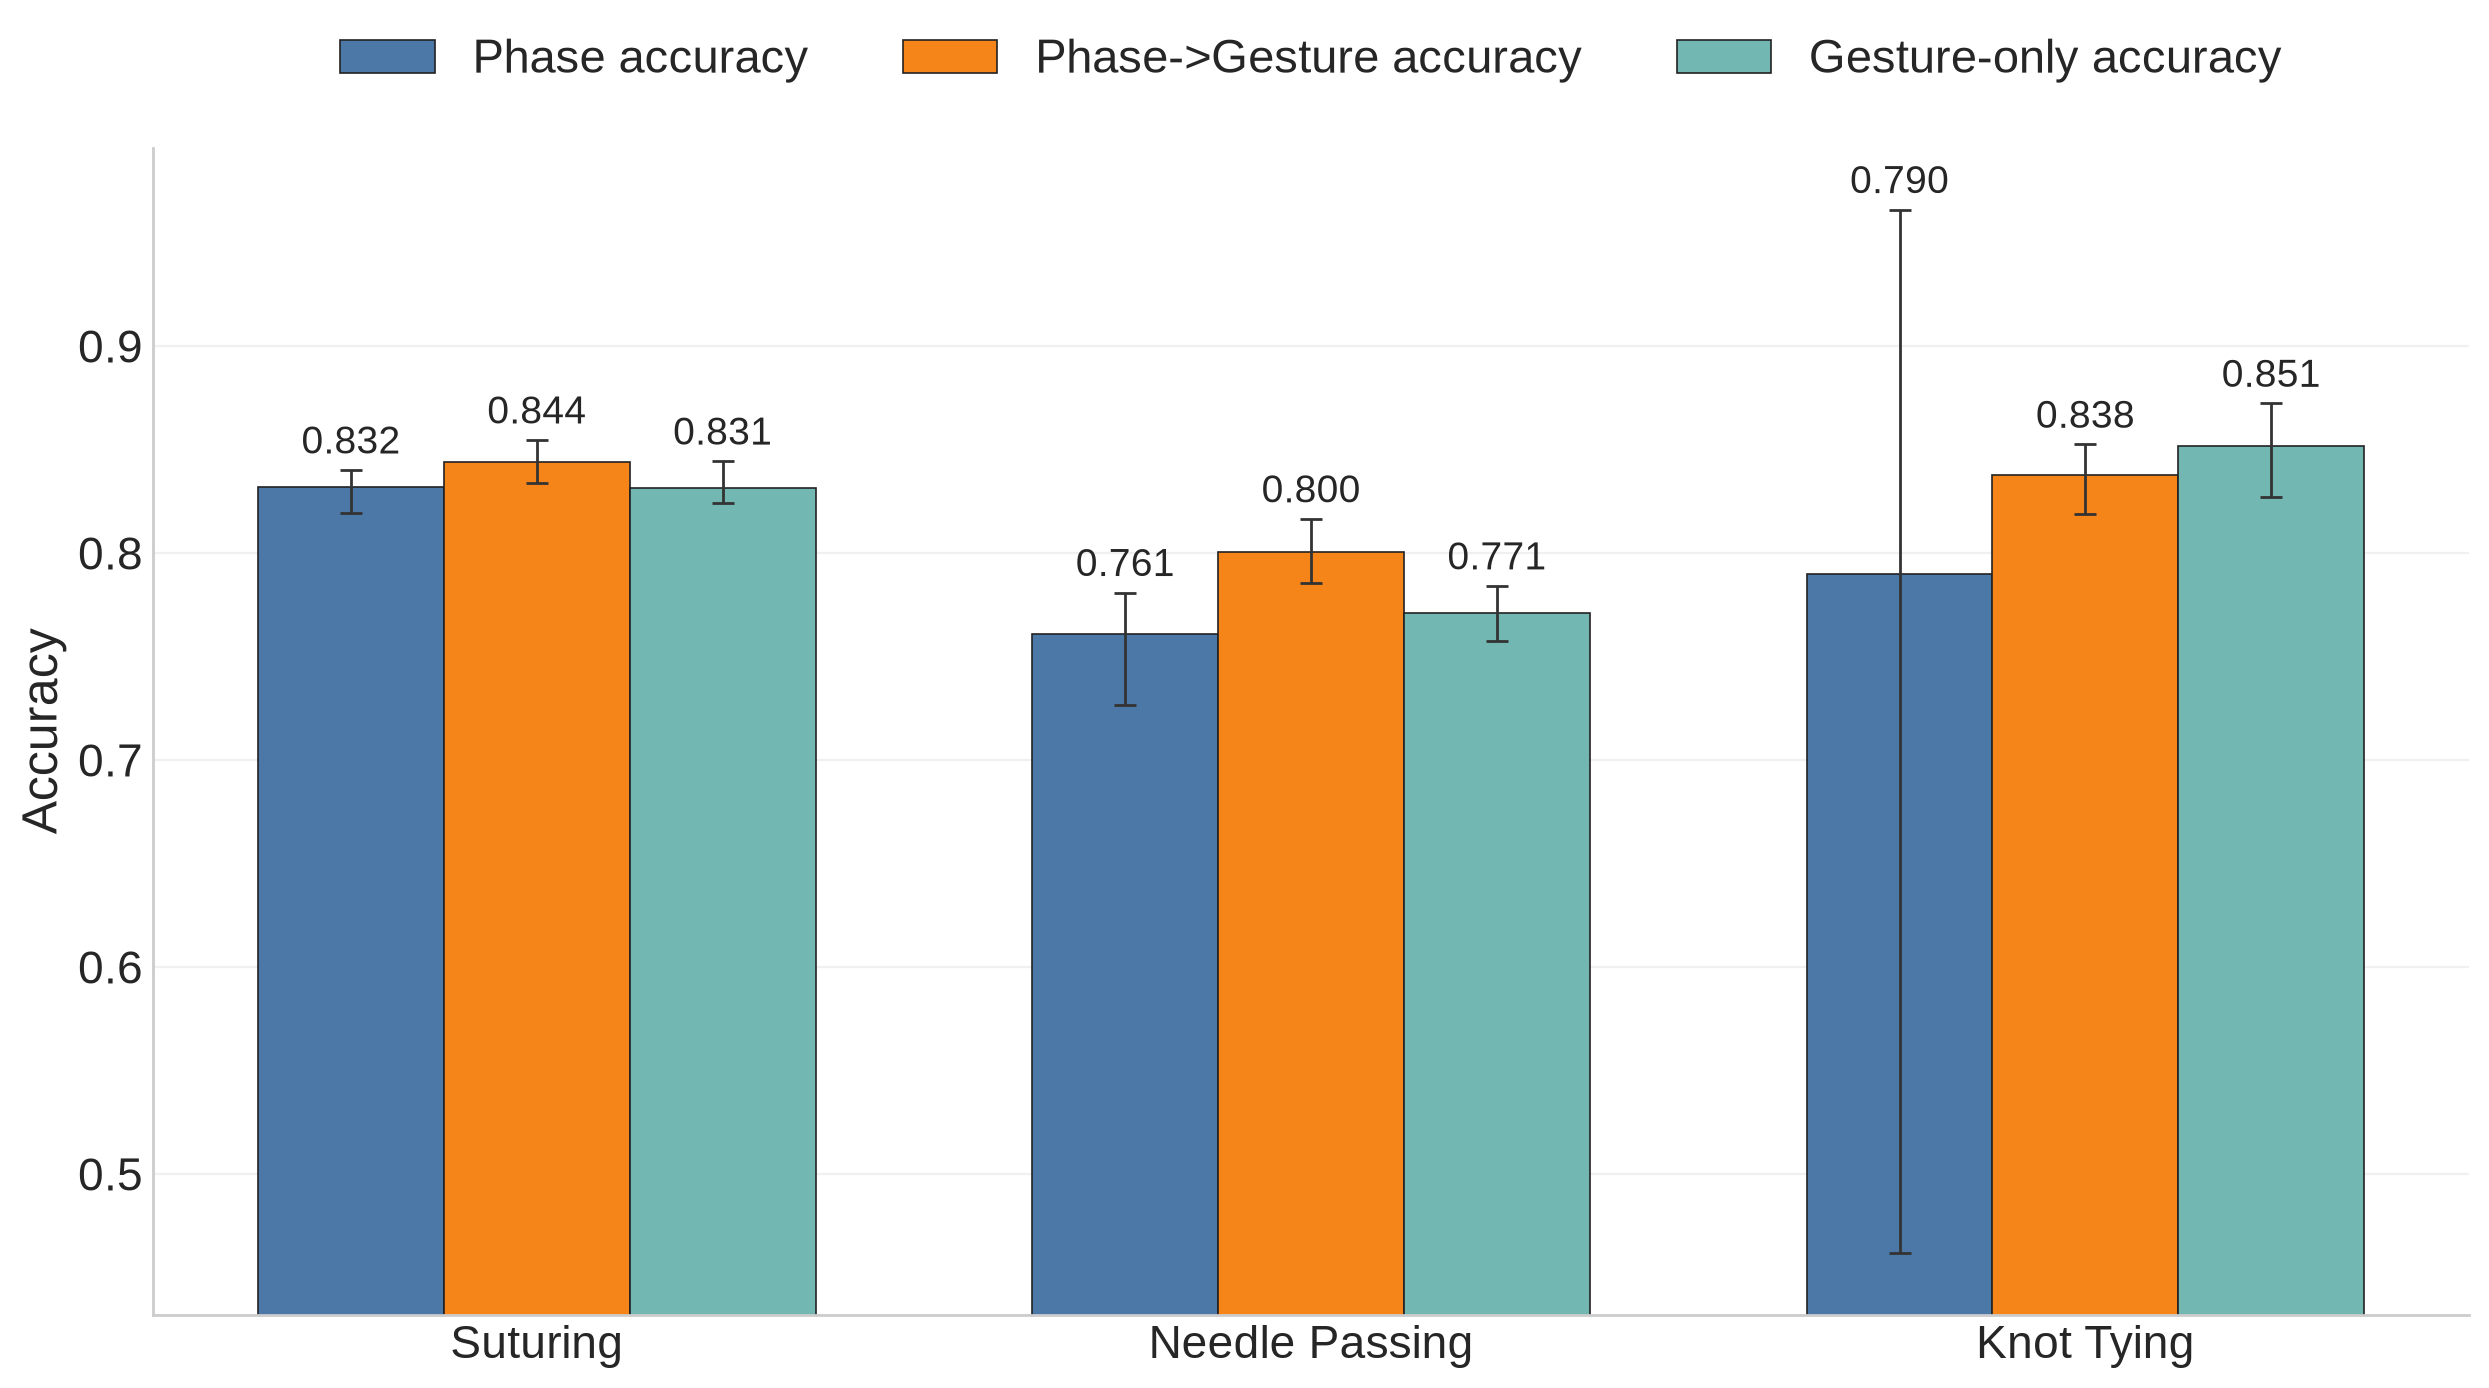

In [10]:
transfer_condition_fig, ax = plt.subplots(figsize=(12.75, 7.2))

x = np.arange(len(task_order))
bar_width = 0.24
colors = ["#4C78A8", "#F58518", "#72B7B2"]

for i, (label, color) in enumerate(zip(transfer_condition_plot.columns, colors)):
    offset = (i - 1) * bar_width
    values = transfer_condition_plot[label].to_numpy()
    mins = transfer_condition_mins[label].to_numpy()
    maxs = transfer_condition_maxs[label].to_numpy()
    yerr = np.vstack([values - mins, maxs - values])
    bars = ax.bar(
        x + offset,
        values,
        bar_width,
        label=label,
        color=color,
        edgecolor="#222222",
        linewidth=0.6,
        yerr=yerr,
        capsize=4,
        error_kw={"elinewidth": 1.0, "capthick": 1.0, "ecolor": "#333333"},
    )
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in transfer_condition_plot[label]], padding=3, fontsize=14)

lower = max(0.0, np.nanmin(transfer_condition_mins.to_numpy()) - 0.03)
upper = min(1.0, np.nanmax(transfer_condition_maxs.to_numpy()) + 0.03)

ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(task_order)
ax.set_ylim(lower, upper)
ax.legend(ncols=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.13))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.28)
ax.grid(axis="x", visible=False)

transfer_condition_fig.tight_layout()
plt.show()


In [11]:
merged_comparison_plot = pd.DataFrame(
    {
        "Gesture from scratch": accuracy_plot["Gesture from scratch"],
        "Gesture by GRS model": accuracy_plot["Gesture by GRS model"],
        "Phase from scratch": phase_accuracy_plot["Phase from scratch"],
        "Gesture->Phase transfer": phase_accuracy_plot["Gesture->Phase transfer"],
    },
    index=task_order,
)

merged_comparison_mins = merged_comparison_plot.copy()
merged_comparison_mins["Gesture->Phase transfer"] = phase_accuracy_mins["Gesture->Phase transfer"]

merged_comparison_maxs = merged_comparison_plot.copy()
merged_comparison_maxs["Gesture->Phase transfer"] = phase_accuracy_maxs["Gesture->Phase transfer"]

merged_comparison_plot


,Gesture from scratch,Gesture by GRS model,Phase from scratch,Gesture->Phase transfer
Suturing,0.836323,0.8321,0.842357,0.826449
Needle Passing,0.801262,0.7844,0.805959,0.752213
Knot Tying,0.860825,0.8440,0.872426,0.826375


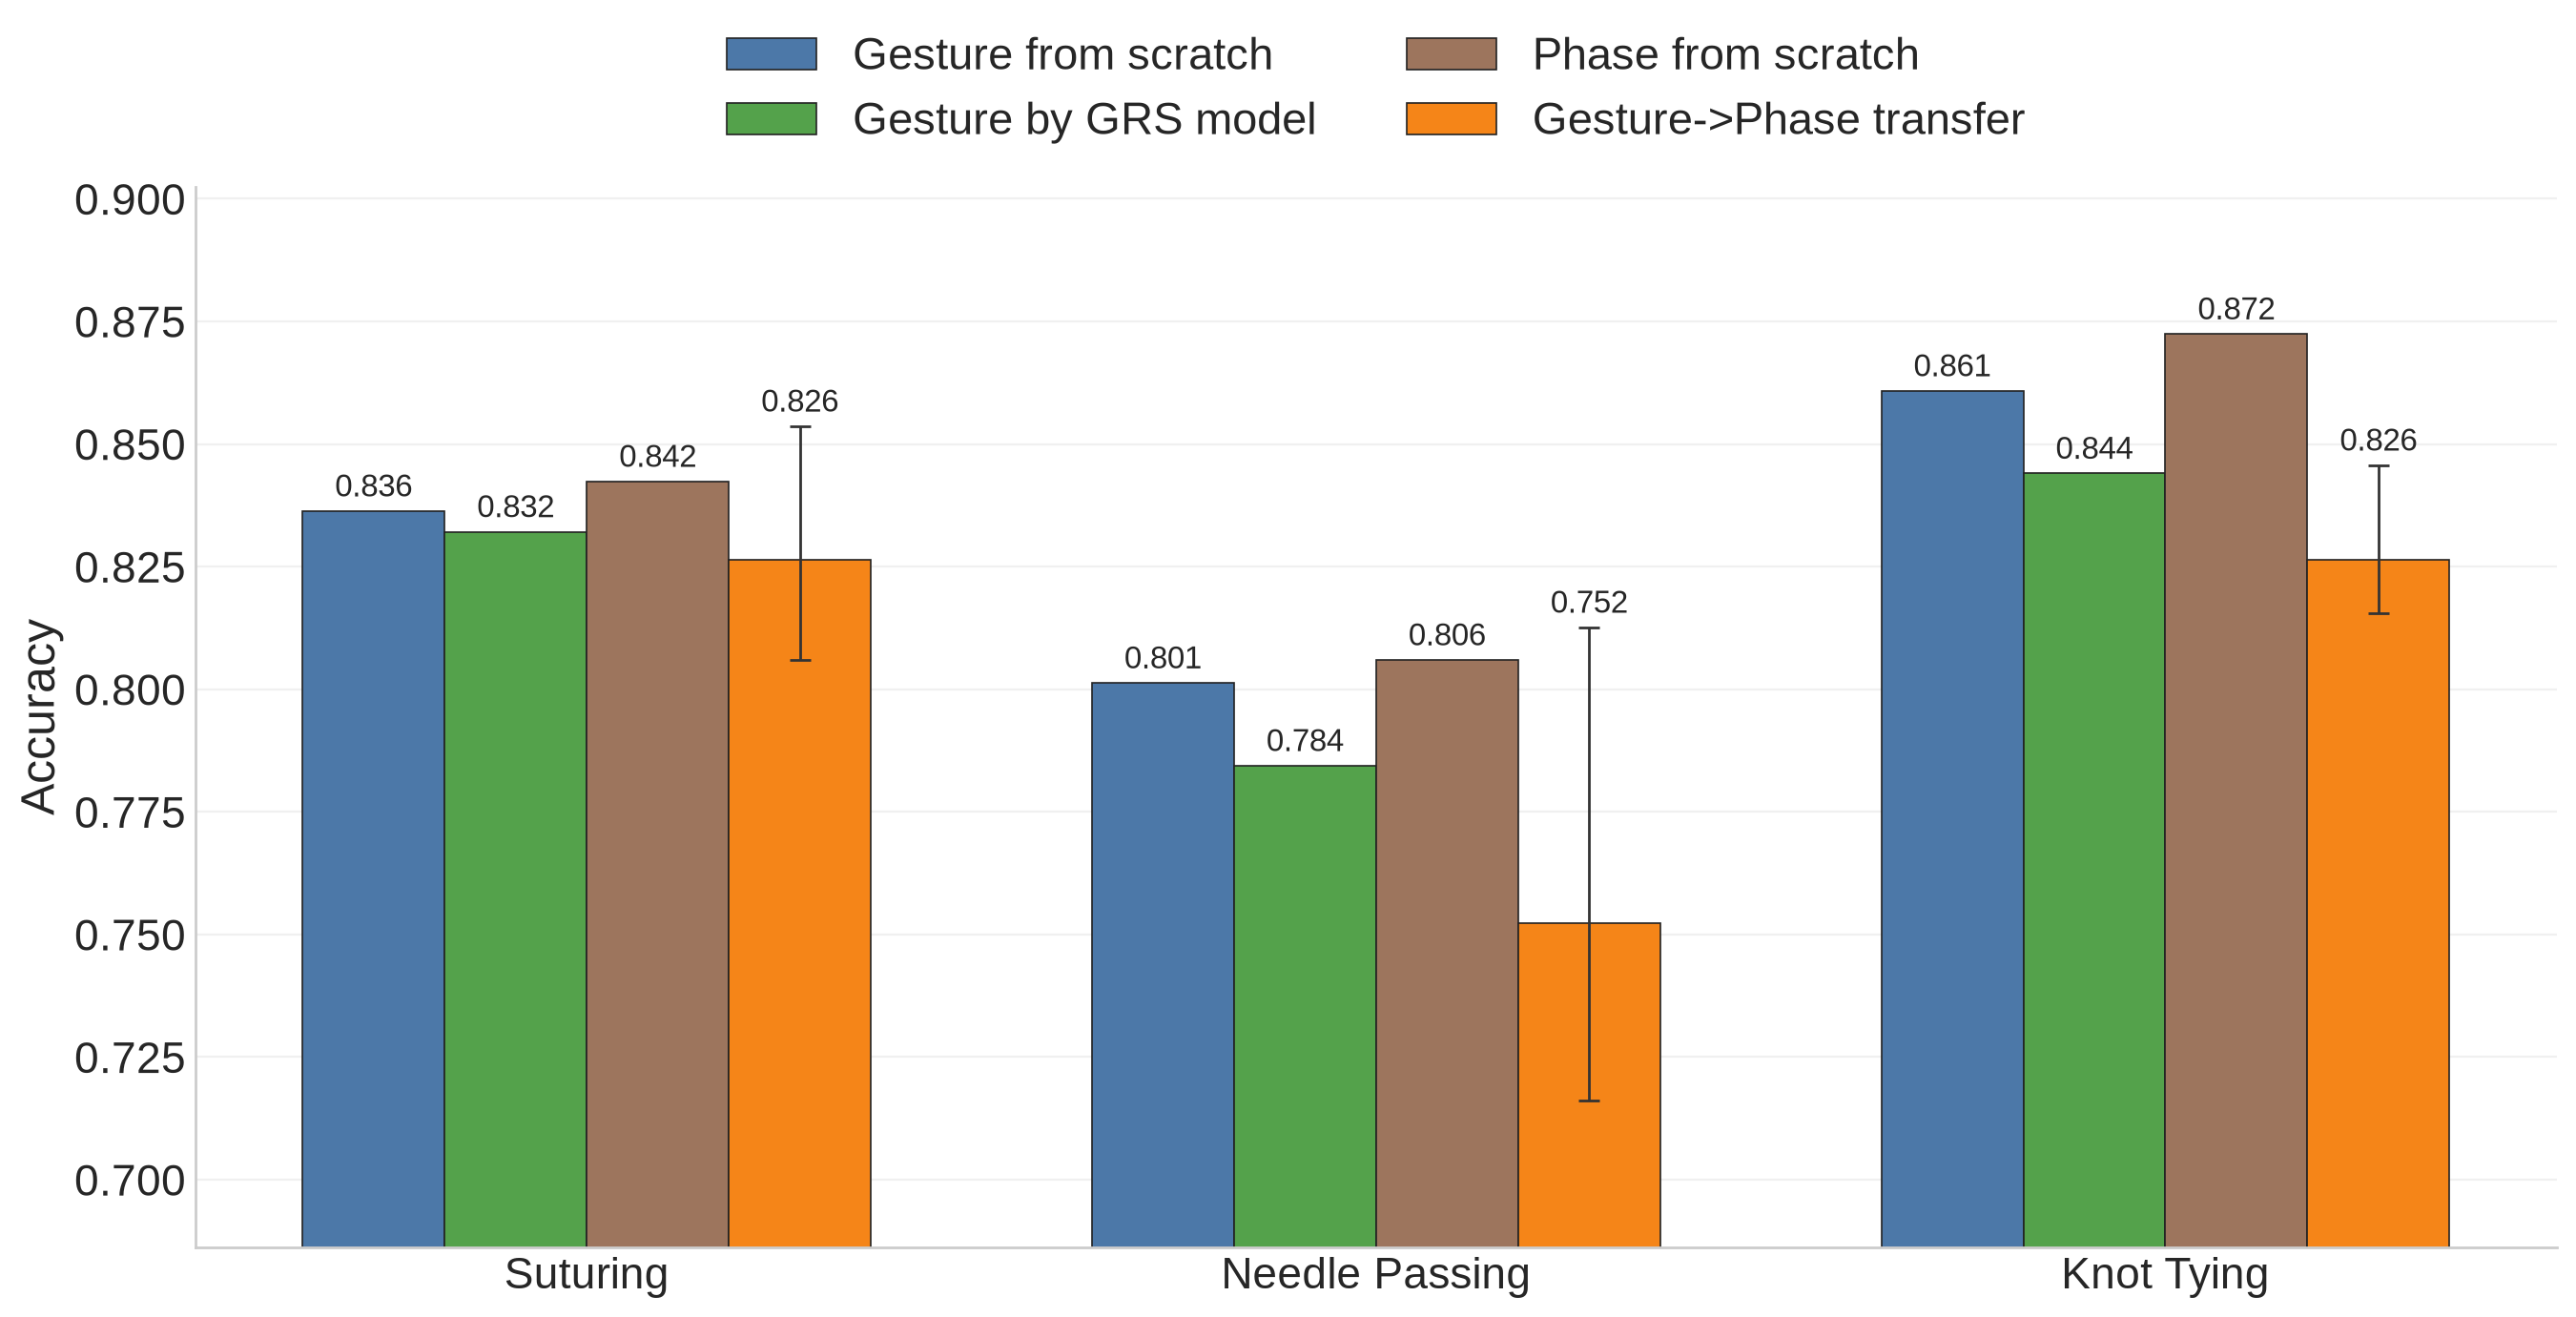

In [12]:
merged_comparison_fig, ax = plt.subplots(figsize=(13.8, 7.2))

x = np.arange(len(task_order))
bar_width = 0.18
colors = ["#4C78A8", "#54A24B", "#9D755D", "#F58518"]

for i, (label, color) in enumerate(zip(merged_comparison_plot.columns, colors)):
    offset = (i - 1.5) * bar_width
    values = merged_comparison_plot[label].to_numpy()
    mins = merged_comparison_mins[label].to_numpy()
    maxs = merged_comparison_maxs[label].to_numpy()
    yerr = np.vstack([values - mins, maxs - values])
    bars = ax.bar(
        x + offset,
        values,
        bar_width,
        label=label,
        color=color,
        edgecolor="#222222",
        linewidth=0.6,
        yerr=yerr if yerr.any() else None,
        capsize=4,
        error_kw={"elinewidth": 1.0, "capthick": 1.0, "ecolor": "#333333"},
    )
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in merged_comparison_plot[label]], padding=3, fontsize=12)

lower = max(0.0, np.nanmin(merged_comparison_mins.to_numpy()) - 0.03)
upper = min(1.0, np.nanmax(merged_comparison_maxs.to_numpy()) + 0.03)

ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(task_order)
ax.set_ylim(lower, upper)
ax.legend(ncols=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.18))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.28)
ax.grid(axis="x", visible=False)

merged_comparison_fig.tight_layout()
plt.show()


## GRS Prediction Results

Task-average MAE, RMSE, and $R^2$ for GRS score prediction.

In [13]:
grs_prediction_metrics = pd.DataFrame(
    [
        ("Suturing", 0.2373, 0.3368, 0.8729),
        ("Needle Passing", 0.1798, 0.2907, 0.8894),
        ("Knot Tying", 0.1284, 0.1942, 0.9576),
    ],
    columns=["Task", "MAE", "RMSE", "R^2"],
).set_index("Task").reindex(task_order)

grs_prediction_metrics


,MAE,RMSE,R^2
Task,,,
Suturing,0.2373,0.3368,0.8729
Needle Passing,0.1798,0.2907,0.8894
Knot Tying,0.1284,0.1942,0.9576


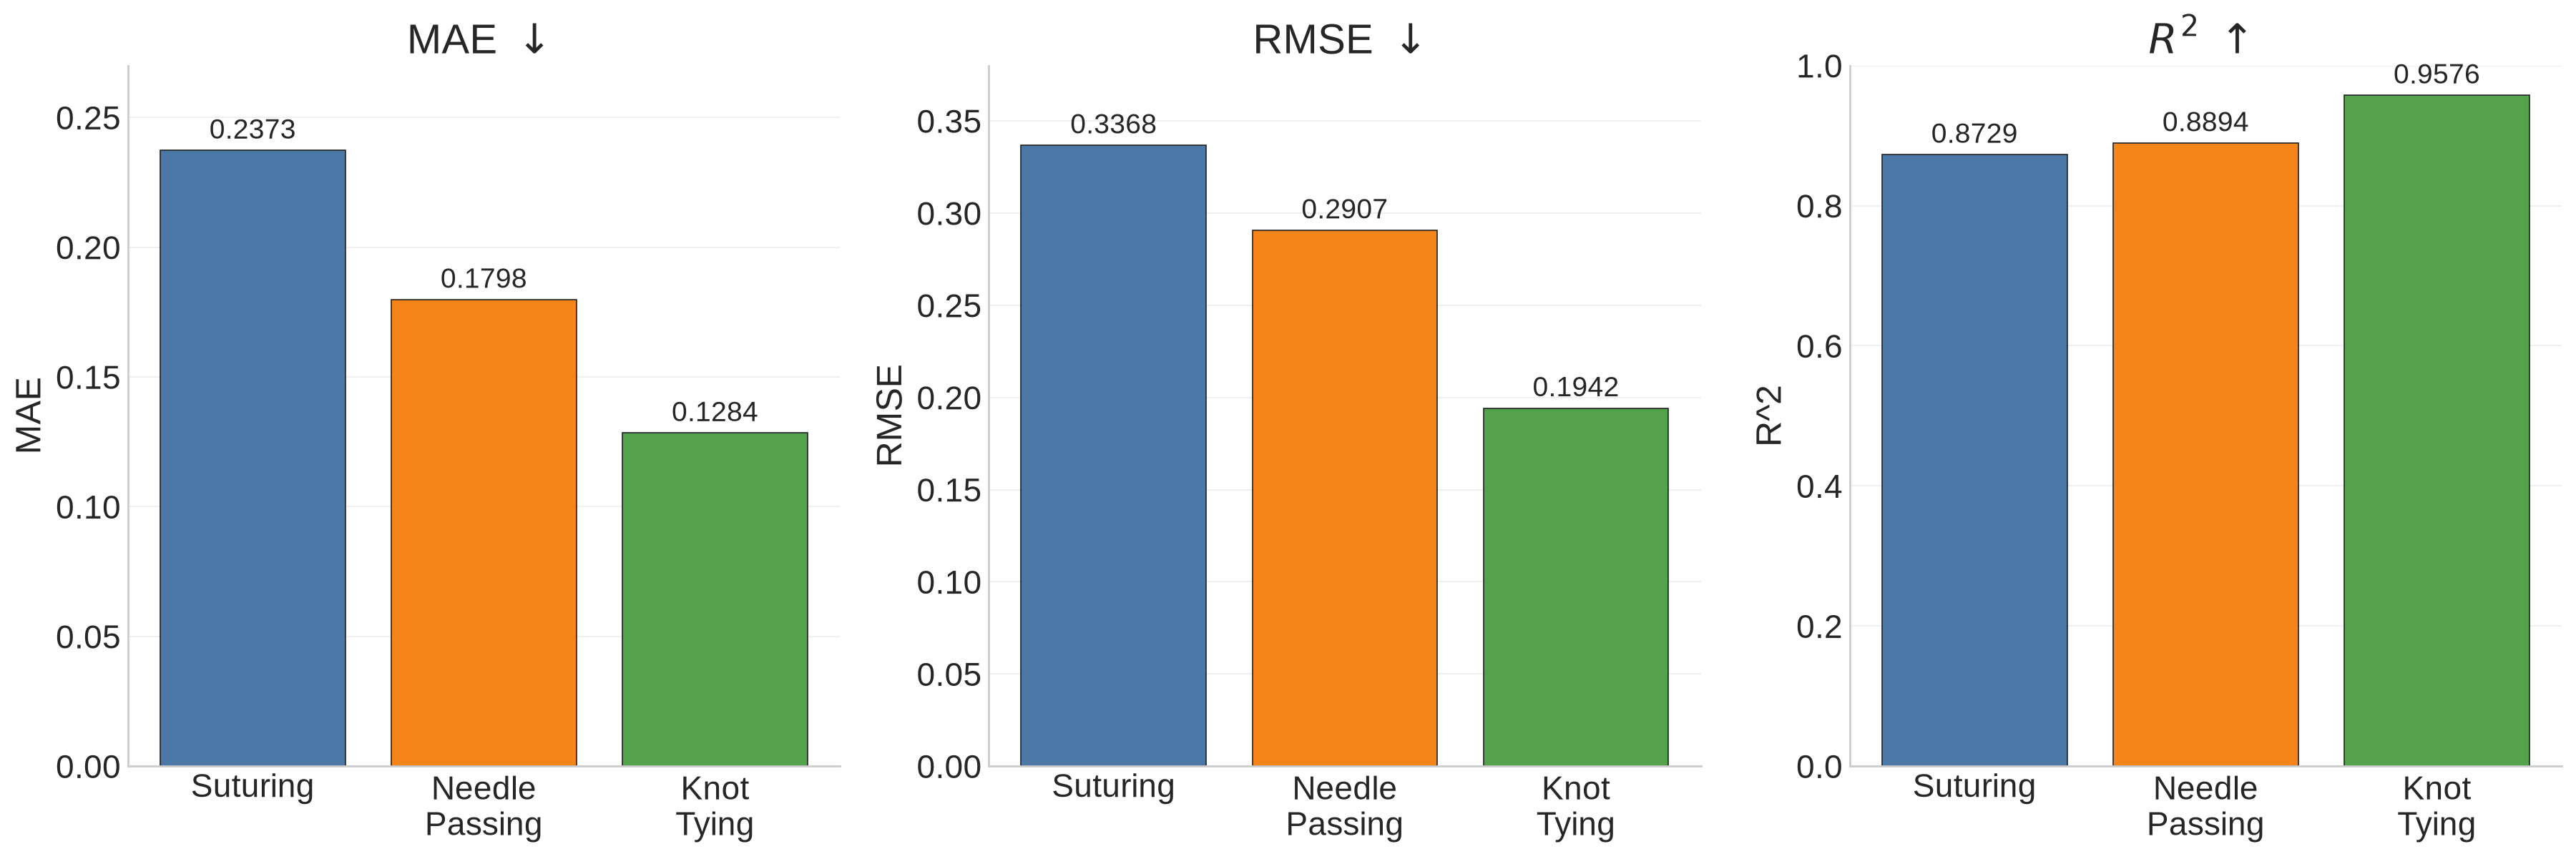

In [14]:
grs_prediction_fig, axes = plt.subplots(1, 3, figsize=(18.3, 6.3))

task_colors = ["#4C78A8", "#F58518", "#54A24B"]
task_tick_labels = ["Suturing", "Needle\nPassing", "Knot\nTying"]
metric_settings = {
    "MAE": {"ylim": (0.0, 0.27), "title": "MAE $\\downarrow$"},
    "RMSE": {"ylim": (0.0, 0.38), "title": "RMSE $\\downarrow$"},
    "R^2": {"ylim": (0.0, 1.0), "title": "$R^2$ $\\uparrow$"},
}

for ax, (metric, settings) in zip(axes, metric_settings.items()):
    values = grs_prediction_metrics[metric]
    bars = ax.bar(
        np.arange(len(values)),
        values,
        color=task_colors,
        edgecolor="#222222",
        linewidth=0.6,
    )
    ax.bar_label(bars, labels=[f"{value:.4f}" for value in values], padding=3, fontsize=14)
    ax.set_title(settings["title"])
    ax.set_ylabel(metric)
    ax.set_xticks(np.arange(len(values)))
    ax.set_xticklabels(task_tick_labels)
    ax.set_ylim(*settings["ylim"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.28)
    ax.grid(axis="x", visible=False)

grs_prediction_fig.tight_layout()
plt.show()


## Stroke Rehab Result Plots

Plots based on `notebooks/stroke_rehab/table1_metrics.tex` and `notebooks/stroke_rehab/table2_uefma.tex`.

In [15]:
primitive_metrics = pd.DataFrame(
    [
        ("Base", 0.568, 0.542, 0.662, 0.631, 0.680, 0.616, 0.634),
        ("Base + patient conditioning", 0.580, 0.557, 0.654, 0.617, 0.701, 0.622, 0.643),
        ("Base + history", 0.715, 0.685, 0.865, 0.788, 0.800, 0.771, 0.786),
    ],
    columns=["Variant", "Reach F1", "Reposition F1", "Rest F1", "Stabilize F1", "Transport F1", "Macro F1", "Accuracy"],
).set_index("Variant")

primitive_deltas = pd.DataFrame(
    [
        ("Patient conditioning", 0.013, 0.015, -0.008, -0.013, 0.021, 0.006, 0.009),
        ("History", 0.147, 0.144, 0.203, 0.157, 0.120, 0.154, 0.152),
    ],
    columns=primitive_metrics.reset_index().columns,
).set_index("Variant")

uefma_metrics = pd.DataFrame(
    [
        ("Base", 0.804, 7.753, 0.331),
        ("Base + patient conditioning", 0.654, 8.074, 0.388),
        ("Base + history", 0.889, 6.144, 0.524),
    ],
    columns=["Variant", "Pearson r", "MAE", "R^2"],
).set_index("Variant")

primitive_metrics


,Reach F1,Reposition F1,Rest F1,Stabilize F1,Transport F1,Macro F1,Accuracy
Variant,,,,,,,
Base,0.568,0.542,0.662,0.631,0.680,0.616,0.634
Base + patient conditioning,0.580,0.557,0.654,0.617,0.701,0.622,0.643
Base + history,0.715,0.685,0.865,0.788,0.800,0.771,0.786


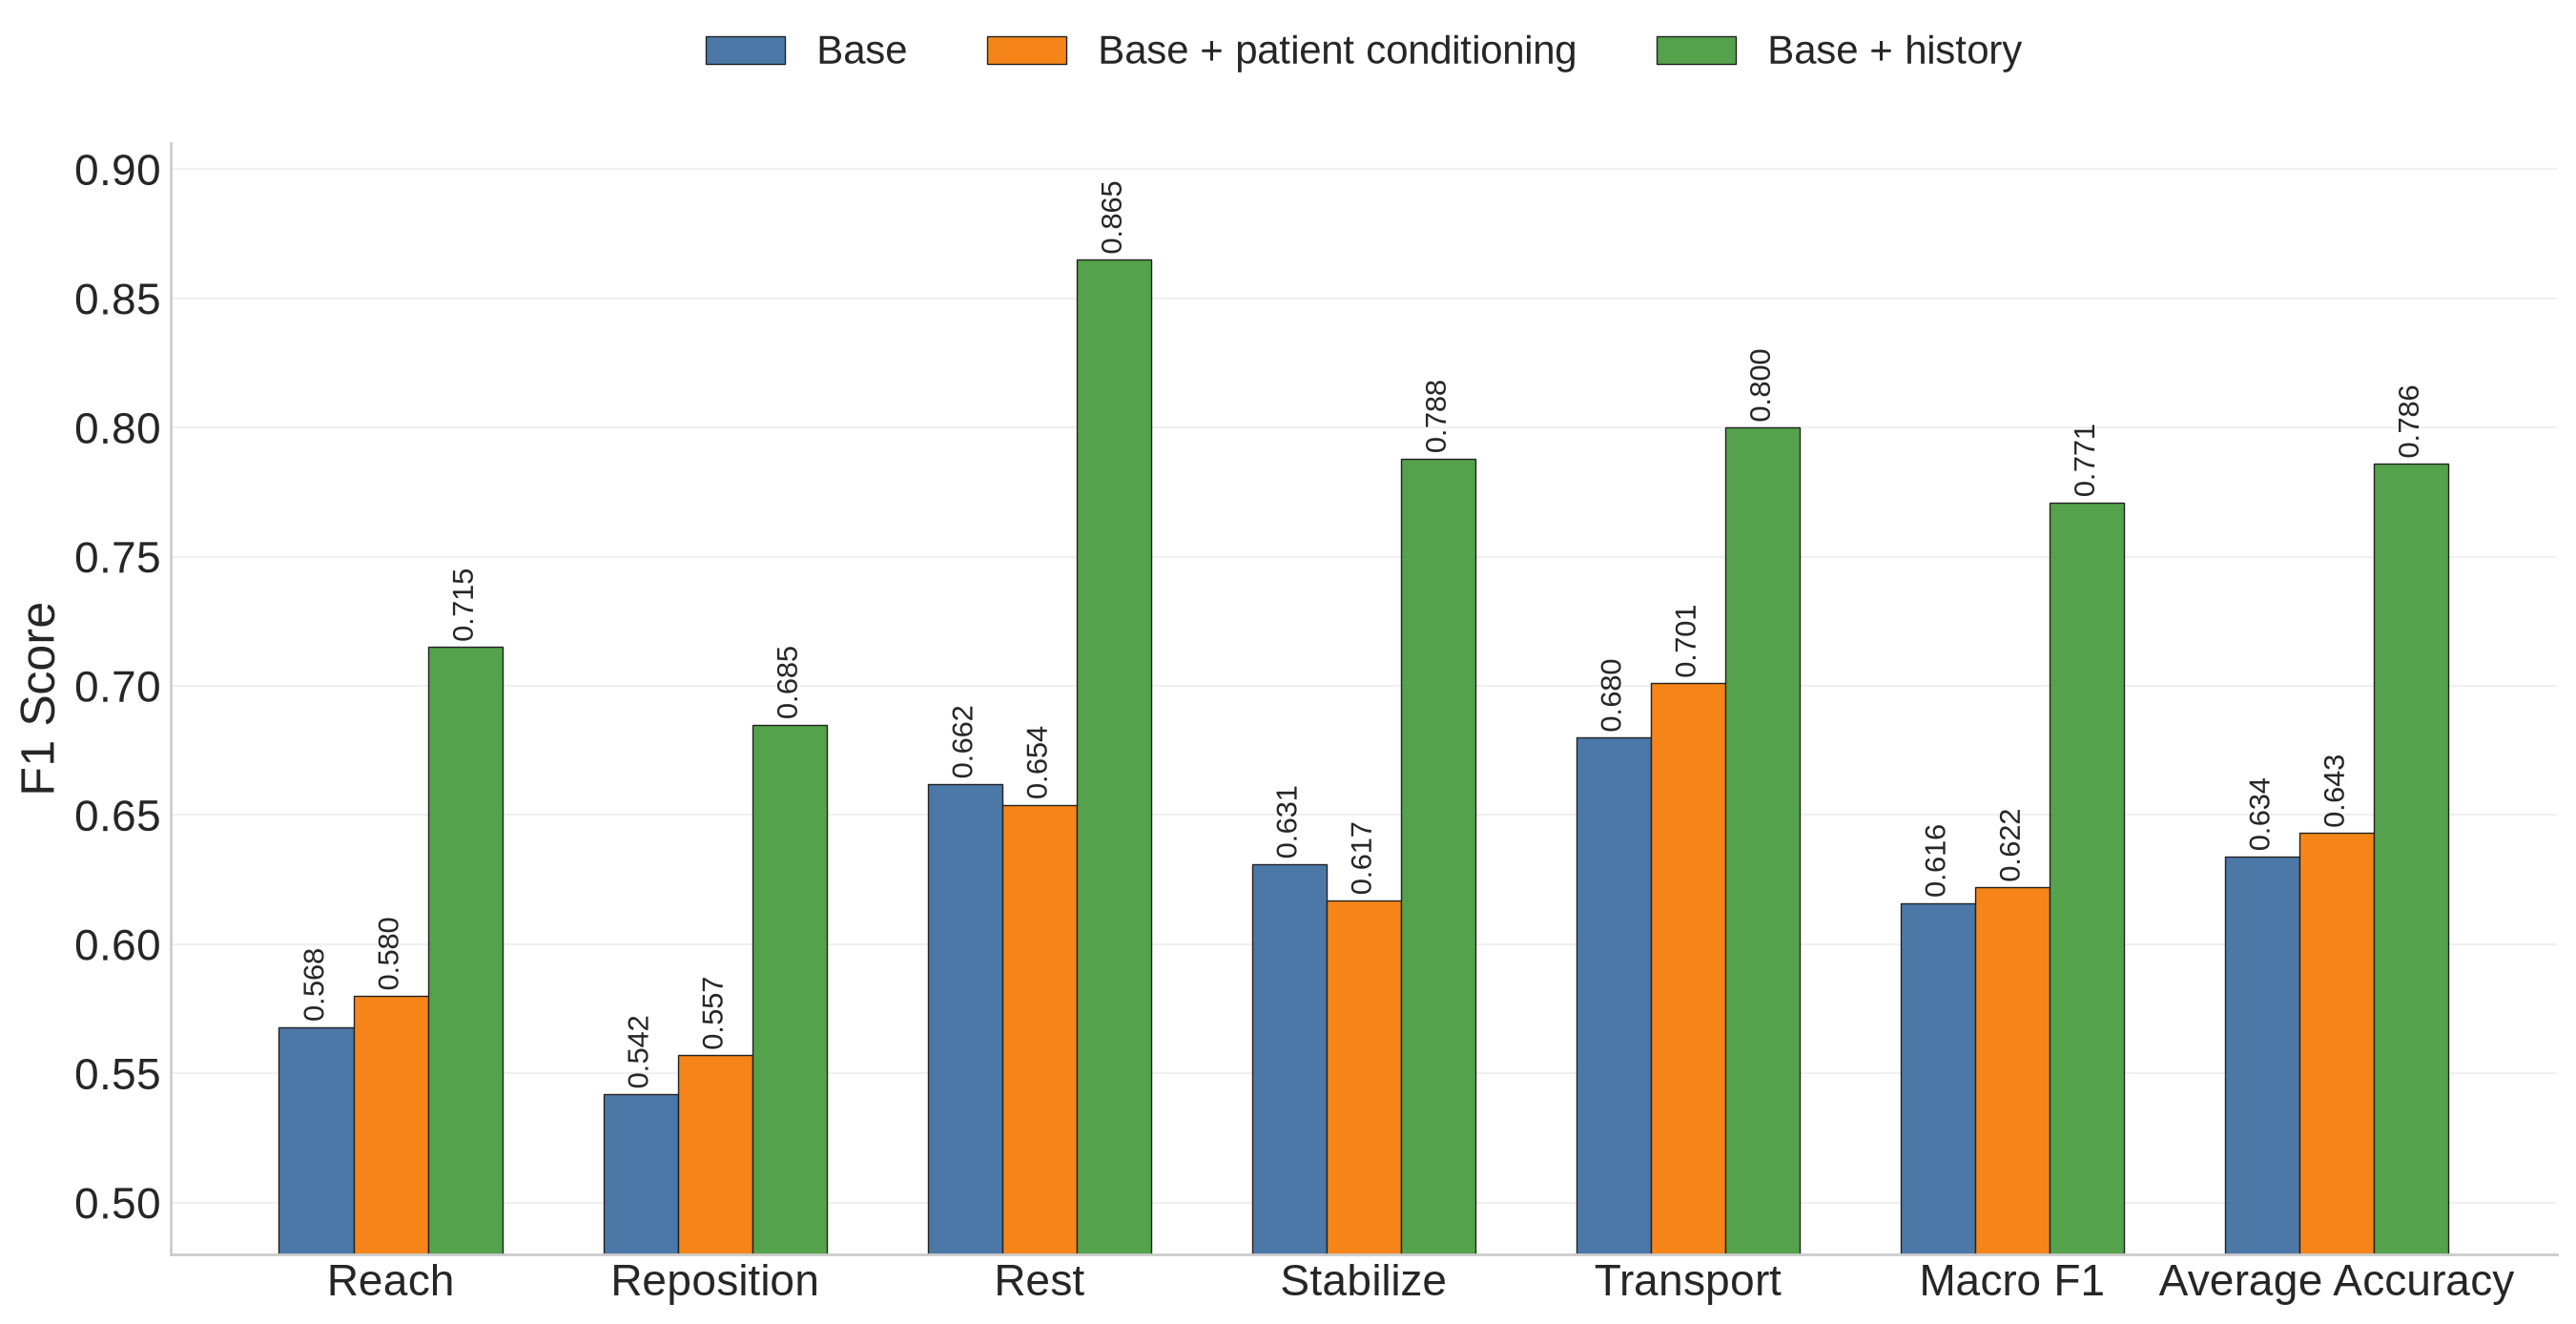

In [16]:
primitive_fig, ax = plt.subplots(figsize=(13.8, 7.2))

metric_order = ["Reach F1", "Reposition F1", "Rest F1", "Stabilize F1", "Transport F1", "Macro F1", "Accuracy"]
metric_labels = ["Reach", "Reposition", "Rest", "Stabilize", "Transport", "Macro F1", "Average Accuracy"]
variant_colors = ["#4C78A8", "#F58518", "#54A24B"]
x = np.arange(len(metric_order))
bar_width = 0.23
for i, (variant, color) in enumerate(zip(primitive_metrics.index, variant_colors)):
    offset = (i - 1) * bar_width
    bars = ax.bar(
        x + offset,
        primitive_metrics.loc[variant, metric_order],
        bar_width,
        label=variant,
        color=color,
        edgecolor="#222222",
        linewidth=0.5,
    )
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in primitive_metrics.loc[variant, metric_order]], padding=2, fontsize=11, rotation=90)

ax.set_ylabel("F1 Score")
ax.set_xticks(x)
ax.set_xticklabels(metric_labels, rotation=0, ha="center")
ax.set_ylim(0.48, 0.91)
ax.legend(ncols=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.13), fontsize=15)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.28)
ax.grid(axis="x", visible=False)

primitive_fig.tight_layout()
plt.show()


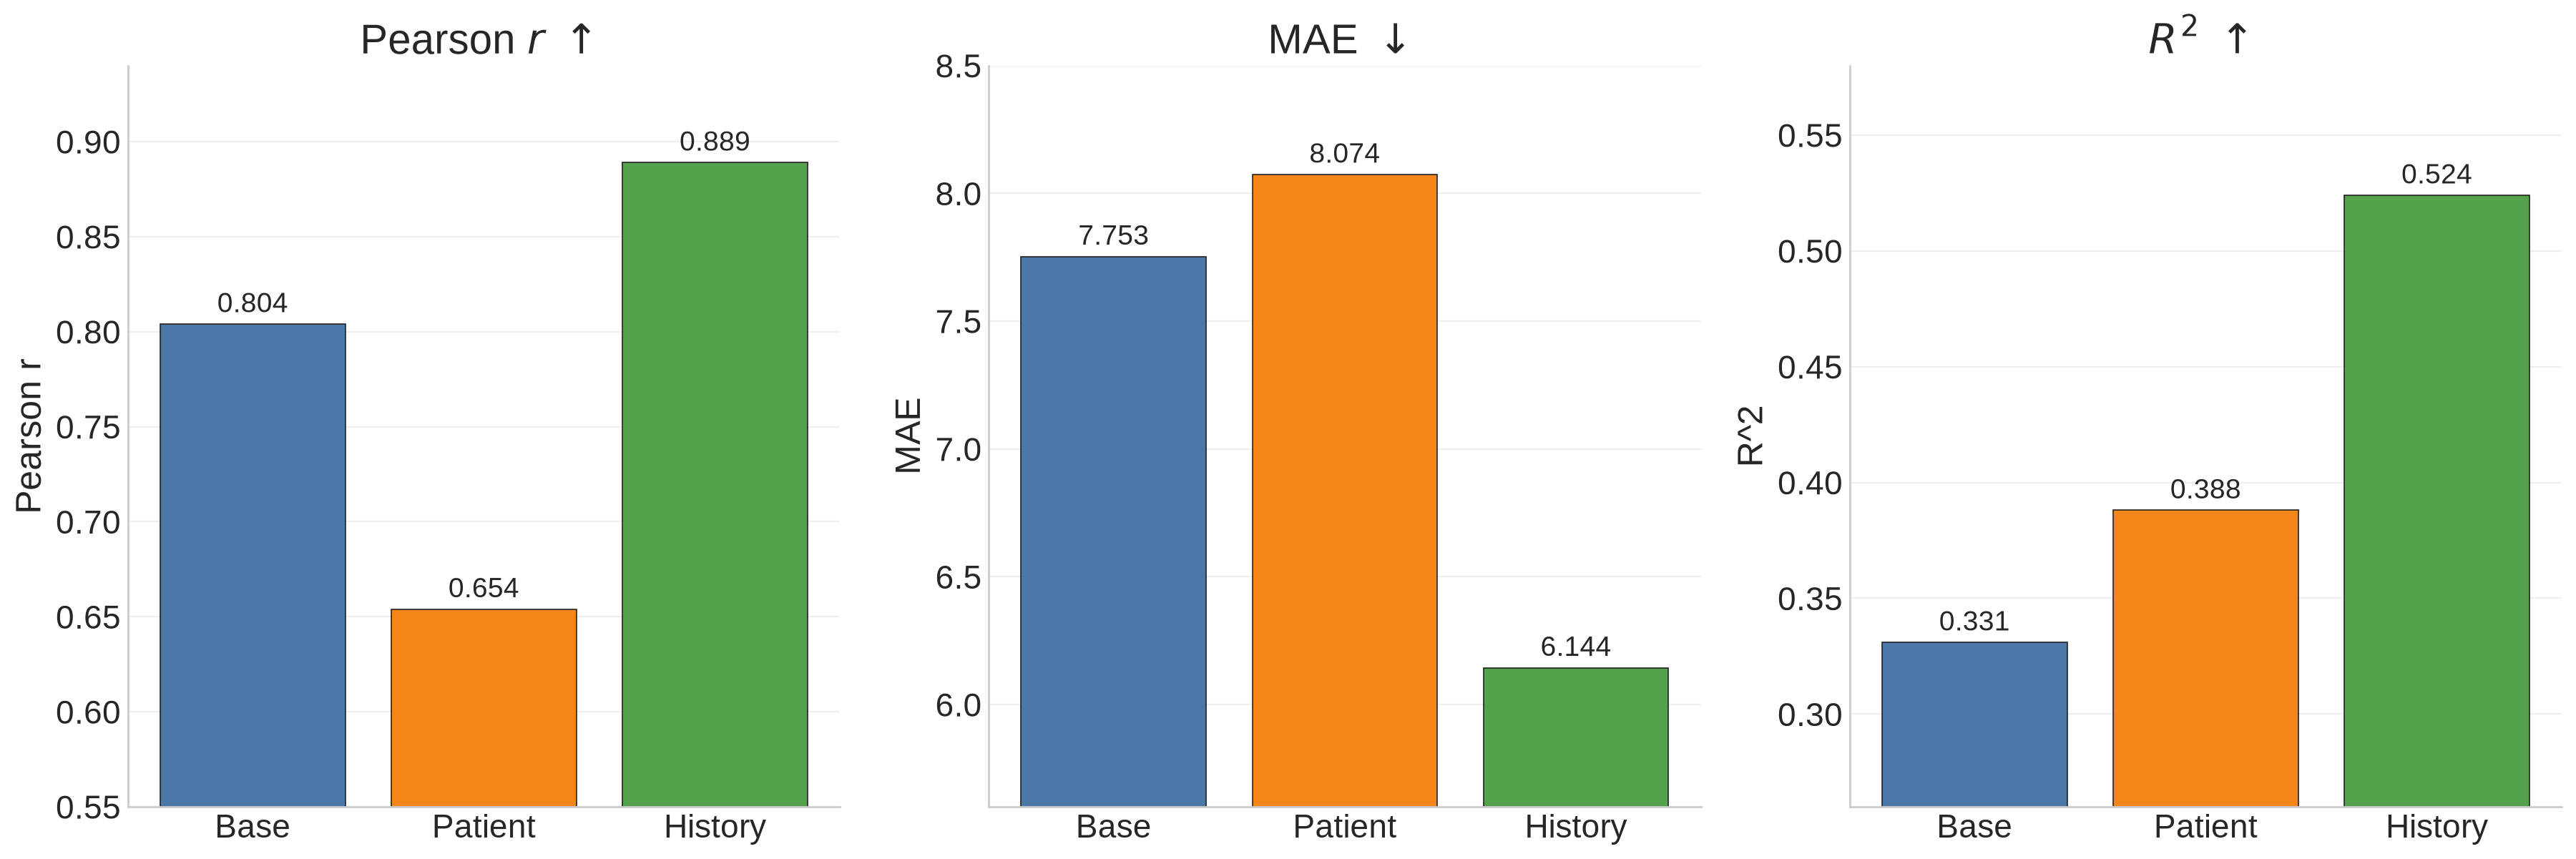

In [17]:
uefma_fig, axes = plt.subplots(1, 3, figsize=(18.3, 6.3))

uefma_colors = ["#4C78A8", "#F58518", "#54A24B"]
metric_settings = {
    "Pearson r": {"ylim": (0.55, 0.94), "ylabel": "Pearson r", "title": "Pearson $r$ $\\uparrow$"},
    "MAE": {"ylim": (5.6, 8.5), "ylabel": "MAE", "title": "MAE $\\downarrow$"},
    "R^2": {"ylim": (0.26, 0.58), "ylabel": "R^2", "title": "$R^2$ $\\uparrow$"},
}

for ax, (metric, settings) in zip(axes, metric_settings.items()):
    values = uefma_metrics[metric]
    bars = ax.bar(
        np.arange(len(values)),
        values,
        color=uefma_colors,
        edgecolor="#222222",
        linewidth=0.6,
    )
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, fontsize=14)
    ax.set_title(settings["title"])
    ax.set_ylabel(settings["ylabel"])
    ax.set_xticks(np.arange(len(values)))
    ax.set_xticklabels(["Base", "Patient", "History"], rotation=0, ha="center")
    ax.set_ylim(*settings["ylim"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.28)
    ax.grid(axis="x", visible=False)

uefma_fig.tight_layout()
plt.show()


In [18]:
output_dir = repo_root / "documents" / "images" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

figures_to_save = {
    "gesture_accuracy": accuracy_fig,
    "phase_accuracy": phase_fig,
    "phase_to_gesture_condition": transfer_condition_fig,
    "gesture_phase_merged_comparison": merged_comparison_fig,
    "grs_prediction_task_averages": grs_prediction_fig,
    "stroke_primitive_performance": primitive_fig,
    "stroke_uefma_alignment": uefma_fig,
}

for name, fig in figures_to_save.items():
    fig.savefig(output_dir / f"{name}.png", bbox_inches="tight")
    fig.savefig(output_dir / f"{name}.pdf", bbox_inches="tight")
